# Kekuatan jaringan dan nilai tambah

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Kekuatan keluar = penjualan antara ke provinsi lain.
--> Kekuatan masuk = pembelian antara dari provinsi lain.
--> Kekuatan = penjualan dan pembelian antarprovinsi.
--> Nilai tambah = jumlah 17 sektor pada target IRIO.
--> Tahun acuan untuk potret silang: 2020 dan 2025.
--> Peringkat 1 = tertinggi.


In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
sys.path.insert(0, str(ROOT / "02 Code" / "IO-IRIO-NA"))
import vizstyle as vs
from vizstyle import (
    DATA, NAVY, TEAL, RUST, GRAY, PAPER, TRILLION,
    apply_style, clean, head, save, mark_2020, rank_desc,
    SHORT, MAP_LABEL, ISLAND_ORDER, ISLAND_COLOR, ISLAND_SHORT,
)

apply_style()
panel = vs.load_strength_panel()

def muat_va(year):
    targets = pd.read_excel(
        DATA / "IRIO" / str(year) / f"IRIO_Estimasi_{year}_RAS.xlsx",
        sheet_name="Targets",
    )
    return targets.groupby("province_name", as_index=False).agg(
        value_added=("target_va", "sum"),
        output=("target_output", "sum"),
    )

frames = []
for year in (2020, 2025):
    piece = panel.loc[panel.year.eq(year)].copy()
    va = muat_va(year)
    piece = piece.merge(va, left_on="province", right_on="province_name", how="left")
    assert piece.value_added.notna().all()
    piece["r_strength"] = rank_desc(piece.strength_total)
    piece["r_out"] = rank_desc(piece.strength_out)
    piece["r_in"] = rank_desc(piece.strength_in)
    piece["r_va"] = rank_desc(piece.value_added)
    piece["r_pagerank"] = rank_desc(piece.pagerank)
    piece["short"] = piece.province.map(SHORT)
    piece["label"] = piece.province.map(MAP_LABEL)
    frames.append(piece)

both = pd.concat(frames, ignore_index=True)
now = both.loc[both.year.eq(2025)].copy()
then = both.loc[both.year.eq(2020)].copy()
assert set(now.province) == set(then.province)
print("spearman strength vs value added 2025",
      round(now.strength_total.corr(now.value_added, method="spearman"), 3))
print("spearman strength vs value added 2020",
      round(then.strength_total.corr(then.value_added, method="spearman"), 3))
print("spearman pagerank vs value added 2025",
      round(now.pagerank.corr(now.value_added, method="spearman"), 3))


## Pasokan dan penggunaan


### Gambar 1. Pasokan terhadap penggunaan
--> Diagonal adalah penjualan dan pembelian yang sama.
--> Provinsi di atas diagonal menjual lebih banyak barang antara ke provinsi lain daripada yang dibelinya dari mereka.
--> Ukuran titik adalah nilai tambah.
--> Warna adalah pulau.


03_supply_use.png


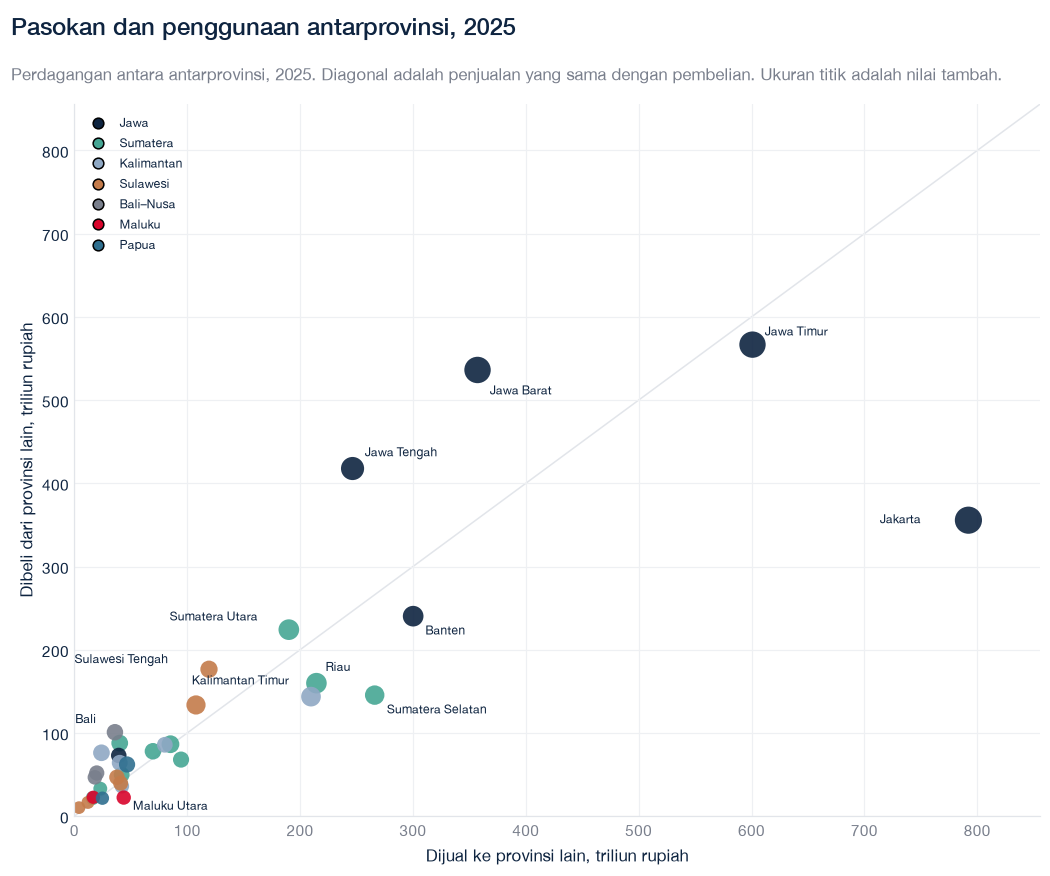

In [2]:
fig, ax = plt.subplots(figsize=(9.6, 8.2))
xmax = (now.strength_out.max() / TRILLION) * 1.08
ax.plot([0, xmax], [0, xmax], color="#E2E5EA", lw=1, zorder=0)
sizes = 36 + 280 * np.sqrt(now.value_added / now.value_added.max())
ax.scatter(now.strength_out / TRILLION, now.strength_in / TRILLION,
           s=sizes, c=now.island.map(ISLAND_COLOR), alpha=0.9,
           linewidths=0, zorder=2)
label_these = {
    "DKI Jakarta", "Jawa Barat", "Jawa Tengah", "Jawa Timur", "Banten",
    "Sumatera Selatan", "Sumatera Utara", "Kalimantan Timur", "Riau",
    "Sulawesi Tengah", "Maluku Utara", "Bali",
}
nudge = {
    "Jawa Barat": (8, -16), "Jawa Tengah": (8, 8), "Jawa Timur": (8, 6),
    "DKI Jakarta": (-58, -2), "Banten": (8, -12), "Sulawesi Tengah": (-88, 4),
    "Maluku Utara": (6, -8), "Sumatera Selatan": (8, -12),
    "Kalimantan Timur": (-78, 8), "Riau": (6, 8), "Sumatera Utara": (-78, 6),
    "Bali": (-26, 6),
}
for r in now.itertuples():
    if r.province not in label_these:
        continue
    dx, dy = nudge.get(r.province, (6, 4))
    ax.annotate(
        r.short,
        (r.strength_out / TRILLION, r.strength_in / TRILLION),
        xytext=(dx, dy), textcoords="offset points",
        fontsize=8, color=NAVY,
    )
handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=ISLAND_COLOR[i],
                      markersize=7, label=ISLAND_SHORT[i]) for i in ISLAND_ORDER]
ax.legend(handles=handles, frameon=False, fontsize=8, loc="upper left")
ax.set_xlim(0, xmax)
ax.set_ylim(0, xmax)
ax.set_xlabel("Dijual ke provinsi lain, triliun rupiah")
ax.set_ylabel("Dibeli dari provinsi lain, triliun rupiah")
clean(ax, grid="both")
head(fig, "Pasokan dan penggunaan antarprovinsi, 2025",
     "Perdagangan antara antarprovinsi, 2025. Diagonal adalah penjualan yang sama dengan pembelian. Ukuran titik adalah nilai tambah.")
save(fig, "03_supply_use.png")

### Gambar 2. Peringkat kekuatan terhadap peringkat nilai tambah
--> Kedua peringkat memakai seluruh 34 provinsi.
--> Peringkat 1 berada di kanan.
--> Garis yang panjang adalah provinsi yang tempatnya pada jaringan transaksi dan tempatnya pada nilai tambah tidak sama.


03_rank_strength_va.png
             short  r_strength  r_va  r_pagerank
 Kalimantan Tengah          13    21          13
Kalimantan Selatan          21    14          17
        Yogyakarta          18    22          16
             Jambi          14    18          21
    Kepulauan Riau          17    13          15
   Bangka Belitung          32    29          33


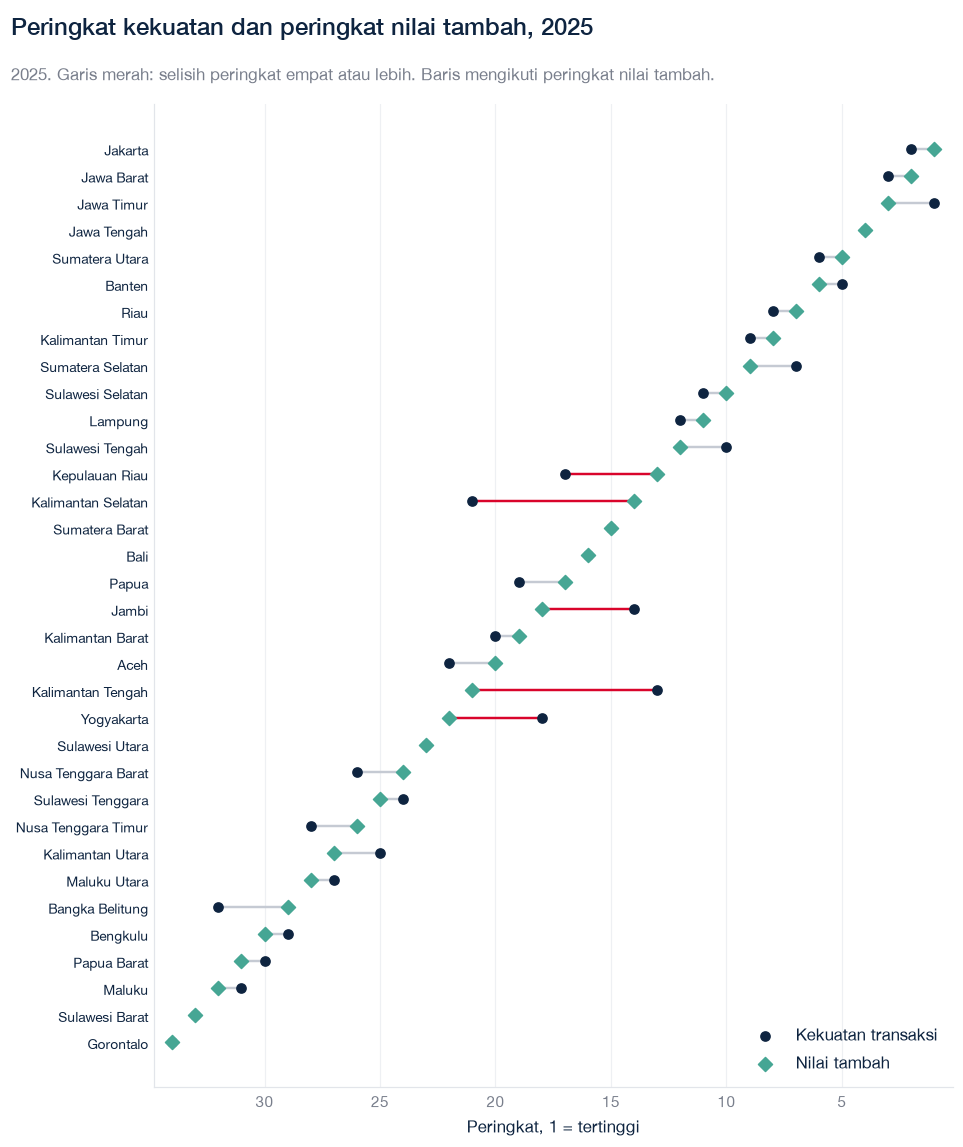

In [3]:
plot = now.sort_values("r_va").reset_index(drop=True)
y = np.arange(len(plot))
fig, ax = plt.subplots(figsize=(8.8, 11.0))
for i, r in plot.iterrows():
    gap = abs(r.r_strength - r.r_va)
    color = RUST if gap >= 4 else "#C5CAD3"
    ax.plot([r.r_strength, r.r_va], [i, i], color=color, lw=1.6, zorder=1)
ax.scatter(plot.r_strength, y, s=36, color=NAVY, zorder=2, label="Kekuatan transaksi")
ax.scatter(plot.r_va, y, s=42, marker="D", color=TEAL, zorder=3, label="Nilai tambah")
ax.set_yticks(y)
ax.set_yticklabels(plot.short, fontsize=9)
ax.set_xlabel("Peringkat, 1 = tertinggi")
ax.set_xlim(34.8, 0.2)
ax.invert_yaxis()
clean(ax, grid="x")
ax.legend(frameon=False, fontsize=11, loc="lower right")
head(fig, "Peringkat kekuatan dan peringkat nilai tambah, 2025",
     "2025. Garis merah: selisih peringkat empat atau lebih. Baris mengikuti peringkat nilai tambah.")
save(fig, "03_rank_strength_va.png")
openings = now.assign(gap=lambda d: (d.r_strength - d.r_va).abs()).sort_values("gap", ascending=False)
print(openings.head(6)[["short", "r_strength", "r_va", "r_pagerank"]].to_string(index=False))

## Pangsa pulau pada kekuatan antarprovinsi
--> Pangsa memakai kekuatan total, yaitu jumlah penjualan ke provinsi lain dan pembelian dari mereka.
--> Provinsi yang hanya berdagang dengan dirinya sendiri tidak masuk ke pangsa.


### Gambar 3. Pangsa pulau pada kekuatan antarprovinsi


03_island_strength_shares.png
island   Java  Sumatra  Kalimantan  ...  Bali and Nusa Tenggara  Maluku  Papua
year                                ...                                       
2017    0.548    0.232       0.094  ...                   0.035   0.008  0.019
2025    0.526    0.232       0.093  ...                   0.032   0.012  0.018

[2 rows x 7 columns]


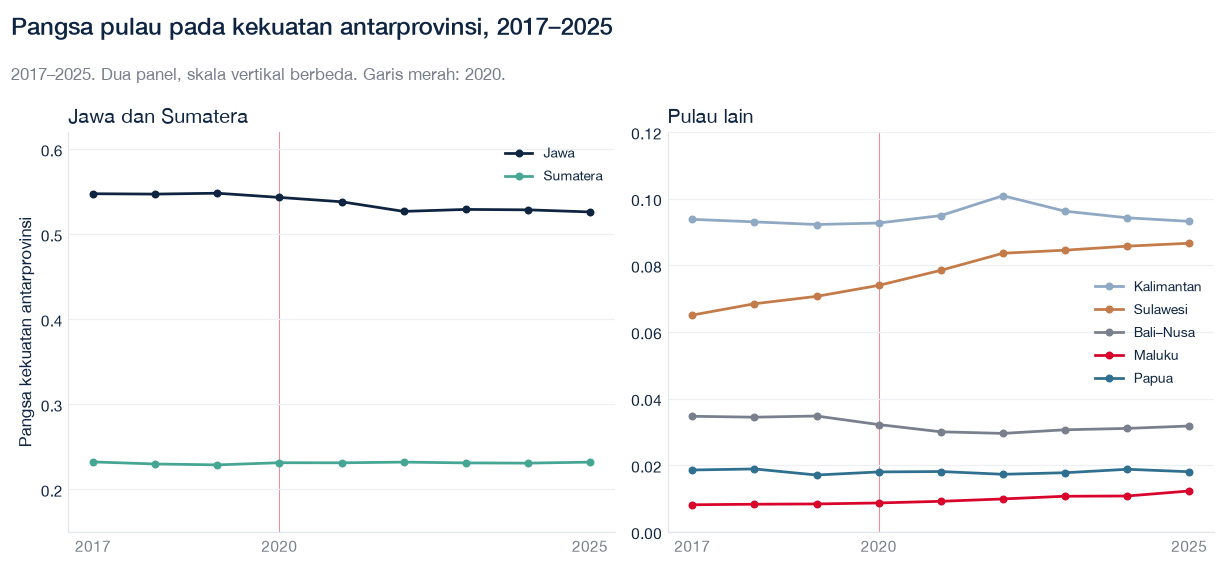

In [4]:
share = (panel.groupby(["year", "island"]).strength_total.sum()
         .unstack("island")
         .reindex(columns=ISLAND_ORDER))
share = share.div(share.sum(axis=1), axis=0)
large = ["Java", "Sumatra"]
small = ["Kalimantan", "Sulawesi", "Bali and Nusa Tenggara", "Maluku", "Papua"]
fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.0), sharex=True)
for ax, names, ylim, title in (
    (axes[0], large, (0.15, 0.62), "Jawa dan Sumatera"),
    (axes[1], small, (0, 0.12), "Pulau lain"),
):
    for name in names:
        ax.plot(share.index, share[name], color=ISLAND_COLOR[name], marker="o", ms=4.2,
                lw=1.8, label=ISLAND_SHORT[name])
    mark_2020(ax)
    ax.set_ylim(*ylim)
    ax.set_xticks([2017, 2020, 2025])
    ax.set_title(title, loc="left", fontsize=13)
    ax.legend(frameon=False, fontsize=9, loc="best")
    clean(ax, grid="y")
axes[0].set_ylabel("Pangsa kekuatan antarprovinsi")
head(fig, "Pangsa pulau pada kekuatan antarprovinsi, 2017–2025",
     "2017–2025. Dua panel, skala vertikal berbeda. Garis merah: 2020.")
save(fig, "03_island_strength_shares.png")
print(share.loc[[2017, 2025]].round(3))

## Barang yang dijual ke luar, menurut komoditas dan tahun
--> Panel IRIO mulai pada 2020.
--> Kekuatan pada gambar di atas menjumlahkan setiap komoditas.
--> Dijual ke luar berarti penjualan antara yang dibeli provinsi lain.
--> Pulau yang sama dan pulau lain adalah dua arah penjualan itu.


### Gambar 4. Nilai yang dijual ke luar, satu sektor pada satu waktu


03_sector_sold_off.png


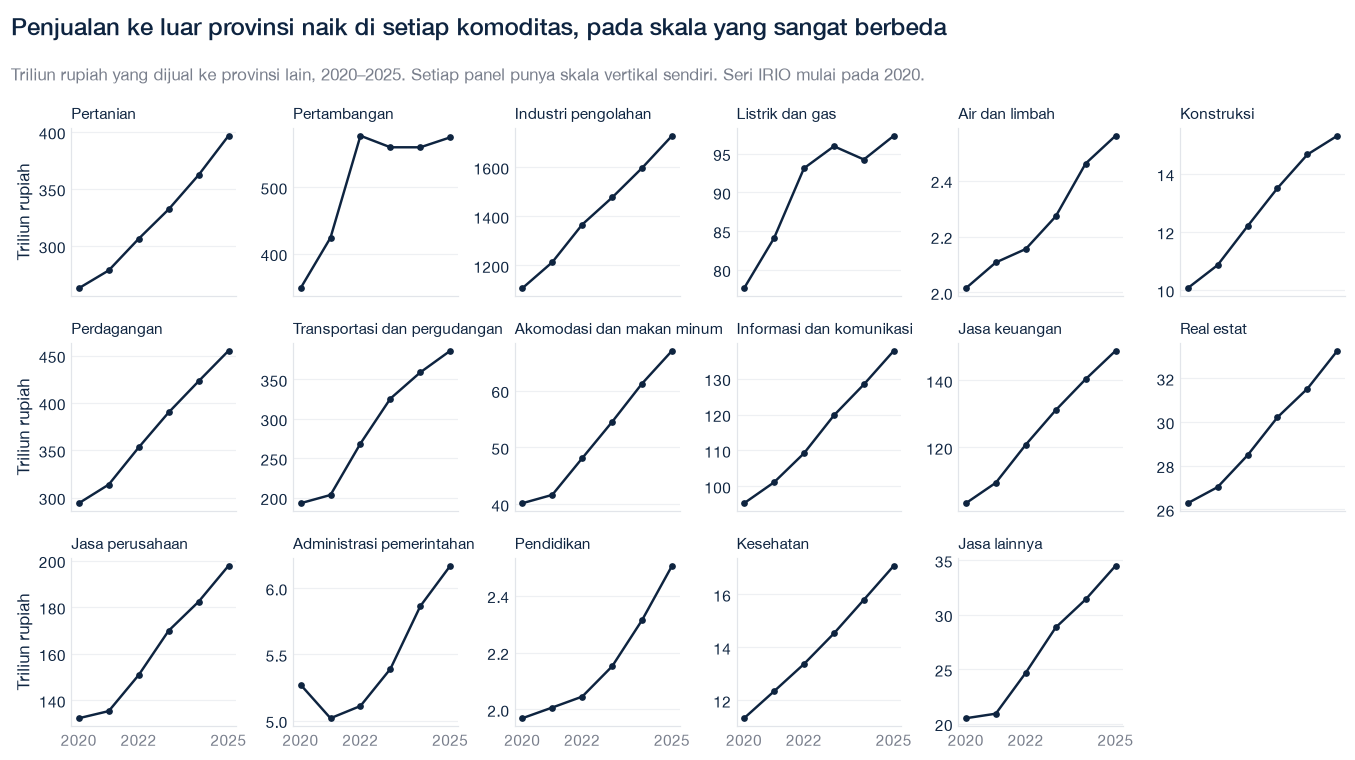

In [5]:
spill = vs.load_sector_spillover()

def draw_away(ax, code):
    sub = spill.loc[spill.origin_sector_code.eq(code)].sort_values("year")
    ax.plot(sub.year, sub.away / vs.TRILLION, color=NAVY, marker="o", ms=3.4, lw=1.6)
    ax.set_xticks([2020, 2022, 2025])

vs.sector_grid(
    vs.SECTOR_ORDER, draw_away,
    "Penjualan ke luar provinsi naik di setiap komoditas, pada skala yang sangat berbeda",
    "Triliun rupiah yang dijual ke provinsi lain, 2020–2025. Setiap panel punya skala vertikal sendiri. Seri IRIO mulai pada 2020.",
    "03_sector_sold_off.png",
    ylabel="Triliun rupiah",
)

### Gambar 5. Pangsa tiap komoditas pada yang dijual ke luar


03_sector_sold_off_share.png


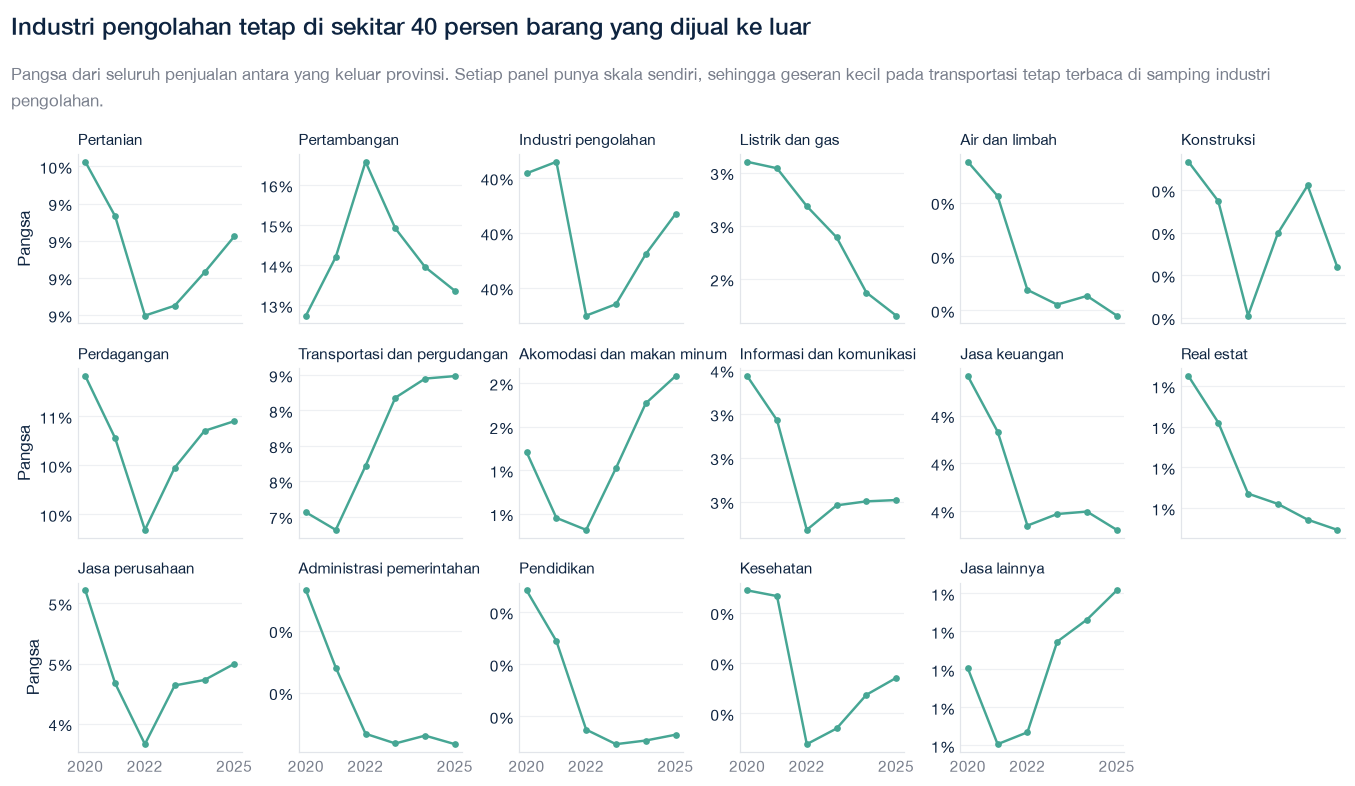

In [6]:
spill = spill.copy()
spill["share"] = spill.away / spill.groupby("year").away.transform("sum")

def draw_share(ax, code):
    sub = spill.loc[spill.origin_sector_code.eq(code)].sort_values("year")
    ax.plot(sub.year, sub.share, color=TEAL, marker="o", ms=3.4, lw=1.6)
    ax.set_xticks([2020, 2022, 2025])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:.0%}"))

vs.sector_grid(
    vs.SECTOR_ORDER, draw_share,
    "Industri pengolahan tetap di sekitar 40 persen barang yang dijual ke luar",
    "Pangsa dari seluruh penjualan antara yang keluar provinsi. Setiap panel punya skala sendiri, sehingga geseran kecil pada transportasi tetap terbaca di samping industri pengolahan.",
    "03_sector_sold_off_share.png",
    ylabel="Pangsa",
)

### Gambar 6. Pulau yang sama dan pulau lain


03_sector_offisland_share.png


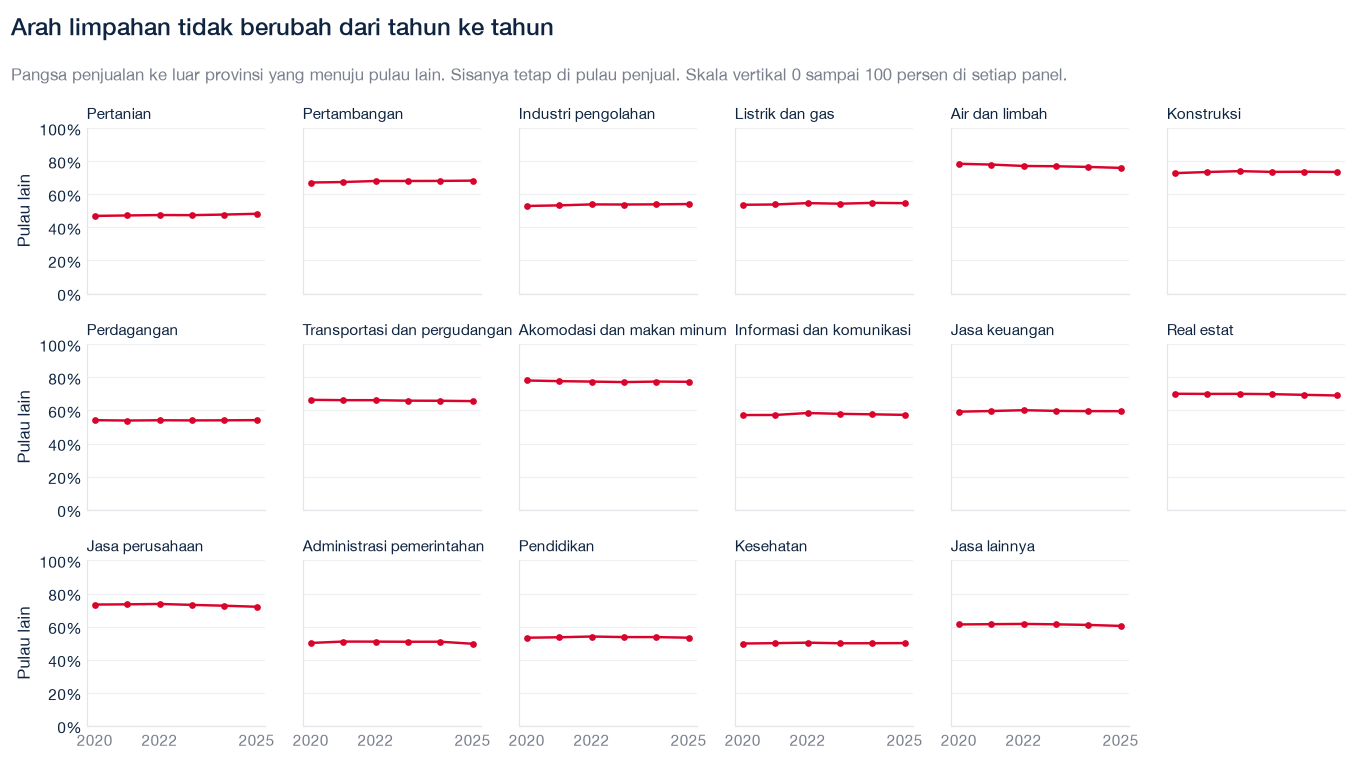

In [7]:
def draw_dest(ax, code):
    sub = spill.loc[spill.origin_sector_code.eq(code)].sort_values("year")
    ax.plot(sub.year, sub.inter_of_away, color=RUST, marker="o", ms=3.4, lw=1.6)
    ax.set_ylim(0, 1)
    ax.set_xticks([2020, 2022, 2025])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:.0%}"))

vs.sector_grid(
    vs.SECTOR_ORDER, draw_dest,
    "Arah limpahan tidak berubah dari tahun ke tahun",
    "Pangsa penjualan ke luar provinsi yang menuju pulau lain. Sisanya tetap di pulau penjual. Skala vertikal 0 sampai 100 persen di setiap panel.",
    "03_sector_offisland_share.png",
    sharey=True,
    ylabel="Pulau lain",
)

## Kekuatan masuk dan keluar, 2020 dan 2025

Gambar pasokan–penggunaan 2025 di atas tetap.
Bagian ini menampilkan kekuatan masuk dan keluar untuk 2020 dan 2025 berdampingan.


### Gambar 7. Pasokan terhadap penggunaan, 2020 dan 2025
--> Diagonal adalah penjualan dan pembelian yang sama.
--> Ukuran titik adalah nilai tambah pada tahun itu.


In [ ]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(12.8, 6.6), sharex=True, sharey=True)
xmax = (both.strength_out.max() / TRILLION) * 1.08
for ax, year in zip(axes, (2020, 2025)):
    sub = both.loc[both.year.eq(year)]
    ax.plot([0, xmax], [0, xmax], color="#E2E5EA", lw=1.0, zorder=0)
    sizes = 28 + 220 * np.sqrt(sub.value_added / both.value_added.max())
    colors = [ISLAND_COLOR[i] for i in sub.island]
    ax.scatter(sub.strength_out / TRILLION, sub.strength_in / TRILLION,
               s=sizes, color=colors, alpha=0.88, zorder=2, linewidths=0)
    for r in sub.itertuples(index=False):
        if r.r_out <= 8 or r.r_in <= 8:
            ax.annotate(
                r.label, (r.strength_out / TRILLION, r.strength_in / TRILLION),
                textcoords="offset points", xytext=(4, 3),
                fontsize=7.5, color=NAVY,
            )
    ax.set_title(str(year), loc="left", fontsize=13, color=NAVY)
    clean(ax)
    ax.set_xlabel("Kekuatan keluar (triliun rupiah)")
axes[0].set_ylabel("Kekuatan masuk (triliun rupiah)")
handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=ISLAND_COLOR[i],
           markersize=7, label=ISLAND_SHORT[i])
    for i in ISLAND_ORDER
]
fig.legend(handles=handles, frameon=False, fontsize=8, ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.02))
head(fig, "Pasokan dan penggunaan antarprovinsi, 2020 dan 2025",
     "Perdagangan antara antarprovinsi. Diagonal: penjualan sama dengan pembelian. Ukuran titik: nilai tambah. Warna: pulau.",
     top=0.86)
save(fig, "03_pasokan_penggunaan_2020_2025.png")
plt.close(fig)


### Gambar 8. Kekuatan keluar dan masuk menurut provinsi
--> Urutan mengikuti nilai 2025.
--> Satu panel untuk penjualan ke luar, satu panel untuk pembelian dari luar.


In [ ]:
def batang_kekuatan(col, judul, anak, fname):
    urut = now.sort_values(col).province.to_numpy()
    y = np.arange(len(urut))
    h = 0.38
    a = then.set_index("province").loc[urut, col].to_numpy() / TRILLION
    b = now.set_index("province").loc[urut, col].to_numpy() / TRILLION
    fig, ax = plt.subplots(figsize=(9.4, 10.6))
    ax.barh(y - h / 2, a, height=h, color=TEAL, label="2020")
    ax.barh(y + h / 2, b, height=h, color=NAVY, label="2025")
    ax.set_yticks(y)
    ax.set_yticklabels([MAP_LABEL[p] for p in urut], fontsize=8.5)
    ax.set_xlabel("Triliun rupiah")
    clean(ax, grid="x")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    head(fig, judul, anak, top=0.92)
    save(fig, fname)
    plt.close(fig)

batang_kekuatan(
    "strength_out",
    "Kekuatan keluar antarprovinsi, 2020 dan 2025",
    "Penjualan antara ke provinsi lain, triliun rupiah. Urutan mengikuti 2025.",
    "03_kekuatan_keluar_2020_2025.png",
)
batang_kekuatan(
    "strength_in",
    "Kekuatan masuk antarprovinsi, 2020 dan 2025",
    "Pembelian antara dari provinsi lain, triliun rupiah. Urutan mengikuti 2025.",
    "03_kekuatan_masuk_2020_2025.png",
)


### Gambar 9. Perubahan peringkat kekuatan dan nilai tambah, 2020–2025
--> Peringkat 1 di kanan.
--> Titik kiri 2020, titik kanan 2025.


In [ ]:
cmp = then[["province", "label", "r_out", "r_in", "r_strength", "r_va"]].merge(
    now[["province", "r_out", "r_in", "r_strength", "r_va"]],
    on="province", suffixes=("_2020", "_2025"),
)
fig, axes = plt.subplots(1, 4, figsize=(13.2, 10.8), sharey=True)
fields = [
    ("r_out", "Kekuatan keluar"),
    ("r_in", "Kekuatan masuk"),
    ("r_strength", "Kekuatan total"),
    ("r_va", "Nilai tambah"),
]
order = cmp.sort_values("r_strength_2025", ascending=False).reset_index(drop=True)
y = np.arange(len(order))
for ax, (col, title) in zip(axes, fields):
    a = order[f"{col}_2020"].to_numpy()
    b = order[f"{col}_2025"].to_numpy()
    for i, (u, v) in enumerate(zip(a, b)):
        color = RUST if abs(v - u) >= 4 else "#C5CAD3"
        ax.plot([u, v], [i, i], color=color, lw=1.4, zorder=1)
    ax.scatter(a, y, s=22, color=TEAL, zorder=2)
    ax.scatter(b, y, s=22, color=NAVY, zorder=2)
    ax.set_xlim(35.8, 0.2)
    ax.set_title(title, loc="left", fontsize=11, color=NAVY)
    clean(ax, grid="x")
    ax.set_xticks([1, 10, 20, 30])
axes[0].set_yticks(y)
axes[0].set_yticklabels(order.label, fontsize=8)
handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=TEAL, markersize=6, label="2020"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=NAVY, markersize=6, label="2025"),
]
fig.legend(handles=handles, frameon=False, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.01), ncol=2)
head(fig, "Perubahan peringkat kekuatan dan nilai tambah, 2020–2025",
     "Peringkat 1 di kanan. Baris mengikuti peringkat kekuatan total 2025. Garis merah: lonjakan empat peringkat atau lebih.",
     top=0.92)
save(fig, "03_peringkat_kekuatan_va_2020_2025.png")
plt.close(fig)
print(cmp.assign(
    d_out=lambda d: d.r_out_2020 - d.r_out_2025,
    d_in=lambda d: d.r_in_2020 - d.r_in_2025,
    d_str=lambda d: d.r_strength_2020 - d.r_strength_2025,
    d_va=lambda d: d.r_va_2020 - d.r_va_2025,
).sort_values("d_str", key=lambda s: s.abs(), ascending=False)
 .head(10)[["label", "r_out_2020", "r_out_2025", "r_in_2020", "r_in_2025", "r_strength_2020", "r_strength_2025", "r_va_2020", "r_va_2025"]]
 .to_string(index=False))


### Gambar 10. Indeks kekuatan keluar dan masuk, 2017–2025
--> Indeks = 100 pada 2017.
--> Enam belas provinsi dengan kekuatan total 2025 tertinggi.


In [ ]:
top = now.nlargest(16, "strength_total").province.tolist()
fig, axes = plt.subplots(4, 4, figsize=(12.4, 9.6), sharex=True, sharey=True)
for ax, prov in zip(axes.ravel(), top):
    sub = panel.loc[panel.province.eq(prov)].sort_values("year")
    ax.plot(sub.year, sub.out_i, color=NAVY, lw=1.6, label="Keluar")
    ax.plot(sub.year, sub.in_i, color=TEAL, lw=1.6, label="Masuk")
    mark_2020(ax)
    ax.set_title(MAP_LABEL[prov], loc="left", fontsize=10, color=NAVY)
    clean(ax, grid="y")
    ax.set_xticks([2017, 2020, 2025])
for ax in axes[-1]:
    ax.set_xlabel("")
handles = [
    Line2D([0], [0], color=NAVY, lw=1.8, label="Kekuatan keluar"),
    Line2D([0], [0], color=TEAL, lw=1.8, label="Kekuatan masuk"),
]
fig.legend(handles=handles, frameon=False, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.01), ncol=2)
head(fig, "Indeks kekuatan keluar dan masuk, 16 provinsi terbesar, 2017–2025",
     "Indeks = 100 pada 2017. Enam belas provinsi dengan kekuatan total 2025 tertinggi. Garis merah: 2020.",
     top=0.90)
save(fig, "03_indeks_kekuatan_masuk_keluar.png")
plt.close(fig)

